# MediAssist-AI — Phase I

Leakage-aware research prototype for historical ICU medication-class recommendation, DDI checks and input validation. **Not a diagnosis, prescribing, or clinically validated system.**

## 1. Project introduction and scope

The model predicts historical ATC level-4 medication classes. It retains unresolved mappings and never asserts that an unrecorded DDI is safe.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / 'integration'))
from phase1_core import load_phase1_data, split_indices, make_inference_features, recommend_from_feature_row
from patient_nlp import extract_patient_information, validate_patient_information
from mediassist_safety import MedicationRegistry, DDIChecker, validate_age_and_reference
from run_end_to_end_demo import build_decision_support_report
print('Package root:', ROOT)

Package root: /Users/vasu/Desktop/mediassist_engine /MediAssist-AI


## 2. Environment and imports

All code below uses only the audited derived tables. The original source CSV bundle is not required for model execution, but is required to rebuild the package.

## 3. Dataset inventory and audit

In [2]:
inventory = pd.read_csv(ROOT / 'data' / 'manifest.csv')
print(inventory[['artifact_path', 'status', 'intended_use']].to_string(index=False))
audit = json.loads((ROOT / 'reports' / 'audit_findings.json').read_text())
print({'visits': audit['tables']['records_final.csv']['rows'], 'patients': audit['patients'], 'ddi_shape': audit['ddi']['shape']})

                                                   artifact_path                         status                           intended_use
                                         /home/claude/README.txt original_referenced_not_copied                        source_of_truth
                                  /home/claude/records_final.csv original_referenced_not_copied                        source_of_truth
                                      /home/claude/voc_final.csv original_referenced_not_copied                        source_of_truth
                                     /home/claude/data_final.csv original_referenced_not_copied                        source_of_truth
                                         /home/claude/SMILES.csv original_referenced_not_copied                        source_of_truth
                            /home/claude/substructure_smiles.csv original_referenced_not_copied                        source_of_truth
                                    /home/claude/ddi_A_

## 4. Preprocessing and leakage prevention

Features use diagnosis, conservative filtered procedures, age bands and sex. All 839 procedure terms flagged medication-like are excluded, along with identifiers, offsets and the undocumented field.

In [3]:
data = load_phase1_data(ROOT)
print(data.feature_metadata)
print('Feature matrix:', data.feature_matrix.shape, 'Targets:', data.targets.shape)

{'diagnosis_features': 2572, 'procedure_features_before_conservative_filter': 2052, 'procedure_codes_removed_as_medication_like': 839, 'demographic_features': 11, 'total_features': 4635, 'procedure_visits_with_any_medication_like_flag': 14528, 'feature_policy': 'diagnosis + conservatively filtered procedures + age bands + gender/missing flags; excludes identifiers, offsets, undocumented field, targets and all medication-like procedure codes'}
Feature matrix: (22988, 4635) Targets: (22988, 107)


## 5. Exploratory data analysis

The following plot uses training data only for medication-class frequency.

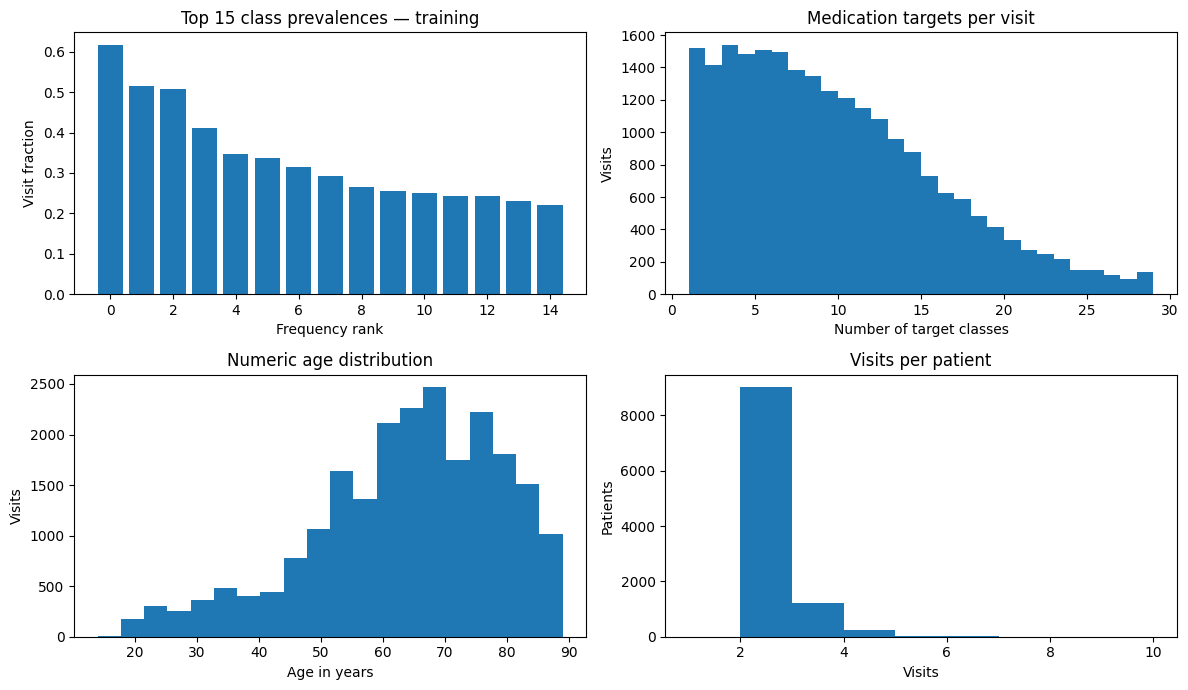

Medication targets per visit: {'min': 1.0, 'mean': 9.538454846006612, 'max': 44.0}


In [4]:
idx = split_indices(data.split)
prevalence = np.asarray(data.targets[idx['train']].mean(axis=0)).ravel()
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes[0,0].bar(range(15), np.sort(prevalence)[-15:][::-1]); axes[0,0].set(title='Top 15 class prevalences — training', xlabel='Frequency rank', ylabel='Visit fraction')
axes[0,1].hist(data.targets.sum(axis=1).A1, bins=range(1, 30)); axes[0,1].set(title='Medication targets per visit', xlabel='Number of target classes', ylabel='Visits')
axes[1,0].hist(data.inputs.age_years.dropna(), bins=20); axes[1,0].set(title='Numeric age distribution', xlabel='Age in years', ylabel='Visits')
visit_counts = data.inputs.groupby('patient_record_index').size(); axes[1,1].hist(visit_counts, bins=range(1, 11)); axes[1,1].set(title='Visits per patient', xlabel='Visits', ylabel='Patients')
plt.tight_layout(); plt.show()
print('Medication targets per visit:', pd.Series(data.targets.sum(axis=1).A1).describe()[['min','mean','max']].to_dict())

## 6. Training/validation/test split

The supplied seed-42 split is by patient, preventing visits from a patient crossing partitions.

In [5]:
split_summary = {name: {'visits': len(rows), 'patients': int(data.inputs.iloc[rows].patient_record_index.nunique())} for name, rows in idx.items()}
split_summary

{'train': {'visits': 16110, 'patients': 7368},
 'val': {'visits': 3431, 'patients': 1578},
 'test': {'visits': 3447, 'patients': 1580}}

## 7. Baseline model

A train+validation frequency ranker is compared using the validation-selected fixed top-k candidate set size.

In [6]:
metrics = json.loads((ROOT / 'models' / 'evaluation_metrics.json').read_text())
pd.DataFrame([metrics['baseline_test_metrics']], index=['frequency baseline'])[['micro_precision','micro_recall','micro_f1','samples_jaccard','recorded_ddi_pair_rate']]

,micro_precision,micro_recall,micro_f1,samples_jaccard,recorded_ddi_pair_rate
frequency baseline,0.330355,0.534951,0.408465,0.246369,0.428571


## 8. Main recommendation model

One-vs-rest sparse linear logistic SGD classifiers were compared at two regularization settings on validation data only; the selected model is then refit on train+validation.

In [7]:
print('Selected alpha:', metrics['selected_alpha'], 'top-k:', metrics['top_k'])
pd.DataFrame({k: v['selected_validation_metrics'] for k,v in metrics['validation_model_selection'].items()}).T[['micro_f1','samples_jaccard']]

Selected alpha: 0.0001 top-k: 15


,micro_f1,samples_jaccard
1e-05,0.402155,0.24228
0.0001,0.439626,0.27136


## 9. Model evaluation

Metrics are held-out test measurements. Recorded DDI pair rate is descriptive only; a missing record is not safety evidence.

In [8]:
pd.DataFrame([metrics['baseline_test_metrics'], metrics['test_metrics']], index=['frequency baseline','sparse linear model'])[['micro_precision','micro_recall','micro_f1','samples_jaccard','recorded_ddi_pair_rate']]

,micro_precision,micro_recall,micro_f1,samples_jaccard,recorded_ddi_pair_rate
frequency baseline,0.330355,0.534951,0.408465,0.246369,0.428571
sparse linear model,0.353544,0.572502,0.437138,0.269438,0.345733


## 10. Medication vocabulary and mapping

Exact index order is retained. All outputs are class-level ATC codes, with individual drug mappings unresolved.

In [9]:
data.mapping[['source_medication_id','atc_code','mapping_status','drug_level_mapping_status','requires_review']].head()

,source_medication_id,atc_code,mapping_status,drug_level_mapping_status,requires_review
0,0,R05CA,class_level_atc_code_only,unmapped,True
1,1,A07AA,class_level_atc_code_only,unmapped,True
2,2,N02AA,class_level_atc_code_only,unmapped,True
3,3,C01BB,class_level_atc_code_only,unmapped,True
4,4,R01AX,class_level_atc_code_only,unmapped,True


## 11. DDI checker

The checker is source-faithful: recorded, no-record-not-proof-of-safety, coverage-unverified, unknown, or duplicate.

In [10]:
checker = DDIChecker()
print('DDI matrix:', checker.A.shape, 'symmetric:', bool((checker.A == checker.A.T).all()))
checker.check_pair(0, 1)

DDI matrix: (107, 107) symmetric: True


{'status': 'no_interaction_record_not_proof_of_safety',
 'action': 'show_notice_no_record_is_not_evidence_of_safety'}

## 12. Age validation and safety-reference handling

Real medication references intentionally remain unavailable. Synthetic rules are exercised only by the dedicated synthetic test suite.

In [11]:
validate_age_and_reference('61', class_id=0)

{'age_years': 61.0,
 'age_group': 'adult',
 'age_issue': None,
 'medication': {'status': 'ok',
  'class_id': 0,
  'atc': 'R05CA',
  'synthetic': False},
 'status': 'reference_unavailable',
 'action': 'show_with_warning_age_suitability_not_assessed'}

## 13. NLP extraction

This transparent rule-based prototype is demonstrated only on fictional text. It was not trained on the dataset because its text column is a placeholder.

In [12]:
fictional_text = ('Fictional research case: 61 years old. Symptoms: cough for 3 days. Current medications: R05CA. Allergies: none. Conditions: none. Research diagnosis indices: 0, 1, 2.')
patient = extract_patient_information(fictional_text)
patient

{'source_text': 'Fictional research case: 61 years old. Symptoms: cough for 3 days. Current medications: R05CA. Allergies: none. Conditions: none. Research diagnosis indices: 0, 1, 2.',
 'age': 61,
 'symptoms': ['cough for 3 days'],
 'symptom_duration': '3 days',
 'current_medications_raw': ['R05CA'],
 'allergies': [],
 'conditions': [],
 'research_diagnosis_indices': [0, 1, 2],
 'uncertain_extractions': [],
 'extraction_method': 'transparent_rule_based_prototype_not_trained_on_clinical_dataset'}

## 14. Patient-information validation

Free-text symptoms are not mapped to undocumented diagnosis vocabulary; reviewed research diagnosis indices are therefore explicitly required.

In [13]:
validate_patient_information(patient, set(data.mapping.atc_code.astype(str)))

{'is_complete_for_demo': True,
 'missing_fields': [],
 'unmapped_medications': [],
 'follow_up_questions': []}

## 15. End-to-end demonstration

The demonstration invokes actual extraction, validation, inference, mapping, DDI checking and age/reference checks. Candidate outputs require review.

In [14]:
decision_support_report = build_decision_support_report()
print(json.dumps(decision_support_report, indent=2))


{
  "prototype_notice": "Fictional research demonstration only; not diagnosis, prescribing, or clinical validation.",
  "original_fictional_input": "Fictional research case: 61 years old. Symptoms: cough for 3 days. Current medications: R05CA. Allergies: none. Conditions: none. Research diagnosis indices: 0, 1, 2.",
  "nlp_extraction": {
    "source_text": "Fictional research case: 61 years old. Symptoms: cough for 3 days. Current medications: R05CA. Allergies: none. Conditions: none. Research diagnosis indices: 0, 1, 2.",
    "age": 61,
    "symptoms": [
      "cough for 3 days"
    ],
    "symptom_duration": "3 days",
    "current_medications_raw": [
      "R05CA"
    ],
    "allergies": [],
    "conditions": [],
    "research_diagnosis_indices": [
      0,
      1,
      2
    ],
    "uncertain_extractions": [],
    "extraction_method": "transparent_rule_based_prototype_not_trained_on_clinical_dataset"
  },
  "patient_information_validation": {
    "is_complete_for_demo": true,
    

## 16. Limitations and conclusion

This prototype does not have clinical free text, verified individual-drug mappings, dosage guidance, severity/mechanism data, paediatric coverage, India-specific validation, provenance/licence confirmation, or a source bundle for complete rebuilding. See `PHASE1_REPORT.md` and `reports/model_evaluation_report.md` for measured results and reproducibility instructions.